# Gallstone classification

This notebook trains an XGBoost model to identify patients with gallstones. The main goal is to detect as many gallstone cases as possible, so sensitivity is the main metric.

The notebook also reports precision, specificity, F1-score, and ROC-AUC alongside the confusion matrix.

The report graphs include the class distribution, an age distribution, the feature correlation matrix, confusion matrices, and SHAP explanations.

# Class-label definitions

- **Gallstone Status:** `0 = Yes`, `1 = No` (target)
- **Gender:** `0 = Male`, `1 = Female`
- **Comorbidity:** `0 = none`, `1 = one`, `2 = two`, `3 = three or more`
- **CAD / Hypothyroidism / Hyperlipidemia / DM:** `0 = No`, `1 = Yes`
- **HFA:** `0 = none` … `4 = very severe`

`Gallstone Status = 1` means **No gallstones**, so every metric in this notebook
explicitly treats **class 0 as the positive (clinical) class**.

Notes: `Comorbidity` is derived from the individual disease flags, and the
body-composition / lipid features are strongly intercorrelated — SHAP splits
credit across correlated features, so read attributions as model behaviour,
not as causal effects. The sample is ~50/50 by design; real-world prevalence is
much lower, so the reported precision will not transfer to a screening population.

In [197]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from sklearn.model_selection import (
    train_test_split,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report,
)
from sklearn.model_selection import StratifiedShuffleSplit


## Loading and processing the data

`DatasetLoader` is responsible for reading the CSV file and preparing the data. `DataProcessor` is used after loading to organise the data and separate the target from the predictors.

The target is `Gallstone Status`. The remaining columns are used as model inputs. The loading and processing methods are placeholders in this version of the notebook.

In [198]:
def gallstone_metrics(y_true, y_pred, prob_gallstone):
    """Single source of truth: class 0 (gallstones present) is the positive class."""
    y_bin = (np.asarray(y_true) == 0).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_gallstones": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "sensitivity_gallstones": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "specificity_gallstones": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_gallstones": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "roc_auc_gallstones": roc_auc_score(y_bin, prob_gallstone),
    }

In [199]:
class DatasetLoader:
    """Load and prepare the Gallstone dataset."""

    def __init__(self, source):
        self.source = source

    def load(self):
        print("Loading dataset from:", self.source)
        try:
            data = pd.read_csv(self.source, low_memory=False)
        except (OSError, ValueError) as error:
            print("Error loading dataset:", error)
            return pd.DataFrame()
        print("Dataset shape:", data.shape)
        return data

    def preprocess(self, data):
        """Clean without silently destroying data.

        `.str.lower()` on a mixed object column turns every non-string into NaN,
        so only genuine string columns are lowercased; anything else is coerced
        to numeric with an explicit warning about unparseable values.
        """
        if data.empty:
            return data

        print("Preprocessing dataset...")
        processed = data.copy()

        for column in processed.select_dtypes(include="object").columns:
            non_null = processed[column].dropna()
            if non_null.map(lambda value: isinstance(value, str)).all():
                processed[column] = processed[column].str.lower()
            else:
                coerced = pd.to_numeric(processed[column], errors="coerce")
                lost = int(coerced.isna().sum() - processed[column].isna().sum())
                if lost:
                    print(f"  WARNING: {column}: {lost} value(s) could not be parsed as numbers")
                processed[column] = coerced

        missing = processed.isna().sum()
        missing = missing[missing > 0]
        if len(missing):
            print("Missing values per column (XGBoost handles NaN natively):")
            print(missing.to_string())
        else:
            print("No missing values.")

        non_numeric = processed.select_dtypes(exclude="number").columns.tolist()
        if non_numeric:
            print(f"WARNING: non-numeric columns remain: {non_numeric}")
        return processed

    def run(self):
        return self.preprocess(self.load())

## 3. Data processing


In [200]:

class DataProcessor:
    TARGET = "Gallstone Status"

    def __init__(self, data):
        self.data = data.copy()

    def process(self):
        if self.data.empty:
            raise ValueError("Dataset is empty.")

        if self.TARGET not in self.data.columns:
            raise KeyError(f"Missing target column: {self.TARGET}")

        if self.data.isna().any().any():
            raise ValueError("Dataset contains missing values.")

        processed = self.data.copy()
        return processed
    
    def split_features_and_target(self):
        processed = self.process()
        x = processed.drop(columns=[self.TARGET])
        y = processed[self.TARGET].astype(int)
        return x, y


## Model training and evaluation

The model uses an 80/20 stratified train/test split. Stratification keeps the two target classes represented in both sets. The random state is fixed so the split can be repeated.

The evaluation focuses on gallstone presence, which is class `0`. Accuracy shows the overall number of correct predictions. Precision shows how many predicted gallstone cases are correct. Recall shows how many actual gallstone cases were found. F1 combines precision and recall, while ROC-AUC measures the ranking of the predicted probabilities.

#NOTE : Noticed that changing the max_depth seems to improve accuracy will validate by comparing.. Just to be sure

In [201]:
class XGBoostModelTrainer:
    """Train and evaluate the gallstone detection model.

    Target encoding is kept unchanged: 0 = gallstones present,
    1 = no gallstones. Class 0 is the clinical positive class.
    """

    def __init__(self, data, test_size=0.25, random_state=42, threshold=0.5):
        if not 0 < test_size < 1:
            raise ValueError("test_size must be between 0 and 1.")
        if not 0 < threshold < 1:
            raise ValueError("threshold must be between 0 and 1.")

        self.data = data
        self.test_size = test_size
        self.random_state = random_state
        self.threshold = threshold


    def create_model(self, max_depth):
        """Create an XGBoost model with a selected tree depth."""
        
        model =  xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=100,
            learning_rate=0.1,
            max_depth=max_depth,
            random_state=self.random_state,
        )
        return model

    def train(self):
        """Process the data once, split it, and fit the XGBoost model."""
        processor = DataProcessor(self.data)
        features, target = processor.split_features_and_target()

        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            features,
            target,
            test_size=self.test_size,
            random_state=self.random_state,
            stratify=target,
        )

        print(
            f"Training set shape: {self.X_train.shape}, "
            f"Test set shape: {self.X_test.shape}"
        )

        model = self.create_model(max_depth=4)

        # The held-out test set is not used for model selection.
        model.fit(self.X_train, self.y_train)
        return model



    def gallstone_probabilities(self, model, features):
        """Return probabilities for class 0, the gallstone class."""
        classes = list(model.classes_)
        if 0 not in classes or 1 not in classes:
            raise ValueError("The model must contain both target classes 0 and 1.")

        return model.predict_proba(features)[:, classes.index(0)]

    def labels_from_probabilities(self, probabilities):
        """Use the configured threshold to classify gallstone risk."""
        return np.where(probabilities >= self.threshold, 0, 1)

    def evaluate(self, model):
        """Return held-out metrics without printing duplicate reports."""
        probabilities = self.gallstone_probabilities(model, self.X_test)
        predictions = self.labels_from_probabilities(probabilities)
        return gallstone_metrics(self.y_test, predictions, probabilities)

    def predict(self, model, new_data):
        """Predict labels and probabilities for new patient records."""
        features = pd.DataFrame(new_data).copy()
        expected_columns = list(self.X_train.columns)
        missing = [column for column in expected_columns if column not in features]
        unexpected = [column for column in features if column not in expected_columns]
        if missing or unexpected:
            raise ValueError(
                f"Missing columns: {missing}; unexpected columns: {unexpected}"
            )

        features = features[expected_columns]
        probability_gallstones = self.gallstone_probabilities(model, features)
        return {
            "predictions": self.labels_from_probabilities(probability_gallstones),
            "probability_gallstones": probability_gallstones,
            "probability_no_gallstones": 1 - probability_gallstones,
        }

    def explain(self, model):
        """Explain changes in P(gallstones) rather than P(no gallstones)."""
        background = self.X_train.sample(
            n=min(100, len(self.X_train)),
            random_state=self.random_state,
        )
        explainer = shap.TreeExplainer(
            model,
            data=background,
            model_output="probability",
            feature_perturbation="interventional",
        )
        no_gallstone_explanation = explainer(self.X_test)

        # XGBoost explains class 1. Negating the values converts the explanation
        # to class 0, the gallstone class.
        return shap.Explanation(
            values=-no_gallstone_explanation.values,
            base_values=1 - no_gallstone_explanation.base_values,
            data=no_gallstone_explanation.data,
            feature_names=list(self.X_test.columns),
        )

    def run(self):
        """Train and evaluate the model without running optional SHAP analysis."""
        model = self.train()
        metrics = self.evaluate(model)
        return model, metrics


## Visualisations and model explanations

The visualisation class creates a target distribution, an age distribution, a correlation matrix, and a confusion matrix. These plots help check the data and compare the predicted labels with the actual labels.

The SHAP bar plot gives an overall ranking of feature importance. The SHAP beeswarm plot shows how individual feature values move predictions towards gallstones or no gallstones. These plots describe the model behaviour and should not be treated as proof that one feature causes the disease.


In [202]:


class DataVisualizer:
    """
    Create exploratory and evaluation plots with readable layouts.
    Template from XGBoost and SHAP documentation, adapted for gallstone disease classification.
    """

    def __init__(self, data):
        """Initialize visualizer with a copy of the dataset."""
        self.data = (
            data.copy()
            if isinstance(data, pd.DataFrame)
            else pd.DataFrame(data)
        )

    def plot_target_distribution(self, target="Gallstone Status"):
        """Plot the number of records in each target class."""
        if target not in self.data.columns:
            raise ValueError(f"Target column not found: {target}")

        counts = self.data[target].value_counts().sort_index()

        if counts.empty:
            raise ValueError("Target column contains no valid values.")

        width = max(8, len(counts) * 1.2)

        figure, axis = plt.subplots(
            figsize=(width, 5),
            layout="constrained"
        )

        bars = axis.bar(
            counts.index.astype(str),
            counts.values,
            color="steelblue",
            edgecolor="black",
            alpha=0.85,
            width=0.6
        )

        axis.set_title(
            f"Distribution of {target}",
            fontsize=14,
            fontweight="bold",
            pad=15
        )
        axis.set_xlabel(target, fontsize=11, labelpad=10)
        axis.set_ylabel("Number of records", fontsize=11)

        axis.tick_params(axis="both", labelsize=10)

        if len(counts) > 5:
            plt.setp(
                axis.get_xticklabels(),
                rotation=30,
                ha="right"
            )

        axis.set_ylim(0, max(counts.values) * 1.15)

        for bar in bars:
            height = bar.get_height()
            axis.annotate(
                f"{int(height)}",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10
            )

        axis.grid(
            axis="y",
            linestyle="--",
            alpha=0.3
        )
        axis.set_axisbelow(True)

        return figure

    def plot_feature_distribution(self, feature, bins=20):
        """Plot a numeric histogram or categorical bar chart."""
        if feature not in self.data.columns:
            raise ValueError(f"Feature column not found: {feature}")

        values = self.data[feature].dropna()

        if values.empty:
            raise ValueError(f"No valid values found for {feature}")

        if pd.api.types.is_numeric_dtype(values):
            figure, axis = plt.subplots(
                figsize=(10, 6),
                layout="constrained"
            )

            axis.hist(
                values,
                bins=bins,
                color="steelblue",
                edgecolor="black",
                alpha=0.8
            )

            axis.set_xlabel(
                feature,
                fontsize=11,
                labelpad=10
            )
            axis.set_ylabel(
                "Number of records",
                fontsize=11
            )

            axis.grid(
                axis="y",
                linestyle="--",
                alpha=0.3
            )

        else:
            counts = values.value_counts().head(20)

            height = max(5, len(counts) * 0.45)

            figure, axis = plt.subplots(
                figsize=(11, height),
                layout="constrained"
            )

            bars = axis.barh(
                counts.index.astype(str),
                counts.values,
                color="steelblue",
                edgecolor="black",
                alpha=0.85
            )

            axis.invert_yaxis()

            axis.set_xlabel(
                "Number of records",
                fontsize=11
            )
            axis.set_ylabel(
                feature,
                fontsize=11
            )

            axis.tick_params(
                axis="y",
                labelsize=9,
                pad=5
            )

            axis.set_xlim(
                0,
                max(counts.values) * 1.15
            )

            for bar in bars:
                width = bar.get_width()
                axis.annotate(
                    f"{int(width)}",
                    xy=(
                        width,
                        bar.get_y() + bar.get_height() / 2
                    ),
                    xytext=(4, 0),
                    textcoords="offset points",
                    ha="left",
                    va="center",
                    fontsize=9
                )

            axis.grid(
                axis="x",
                linestyle="--",
                alpha=0.3
            )

        axis.set_title(
            f"Distribution of {feature}",
            fontsize=14,
            fontweight="bold",
            pad=15
        )

        axis.tick_params(axis="x", labelsize=10)
        axis.set_axisbelow(True)

        return figure

    def plot_correlation_matrix(self):
        """Plot correlations between numeric features."""
        numeric_data = self.data.select_dtypes(
            include="number"
        )

        if numeric_data.empty:
            raise ValueError(
                "At least one numeric column is required."
            )

        correlations = numeric_data.corr()

        labels = correlations.columns.tolist()
        n_features = len(labels)

        # Automatically increase plot size for more features.
        figure_size = max(10, n_features * 0.6)

        figure, axis = plt.subplots(
            figsize=(figure_size, figure_size),
            layout="constrained"
        )

        image = axis.imshow(
            correlations,
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            interpolation="nearest",
            aspect="equal"
        )

        colorbar = figure.colorbar(
            image,
            ax=axis,
            shrink=0.8,
            pad=0.02
        )
        colorbar.set_label(
            "Correlation",
            fontsize=11
        )

        axis.set_xticks(np.arange(n_features))
        axis.set_yticks(np.arange(n_features))

        axis.set_xticklabels(
            labels,
            rotation=90,
            ha="center",
            fontsize=9
        )
        axis.set_yticklabels(
            labels,
            fontsize=9
        )

        axis.tick_params(
            axis="both",
            which="major",
            pad=6,
            length=0
        )

        axis.set_title(
            "Correlation Matrix",
            fontsize=15,
            fontweight="bold",
            pad=20
        )

        # Display correlation values when the matrix
        # is small enough to remain readable.
        if n_features <= 12:
            for row in range(n_features):
                for col in range(n_features):
                    value = correlations.iloc[row, col]

                    if np.isnan(value):
                        text = "N/A"
                        text_color = "black"
                    else:
                        text = f"{value:.2f}"
                        text_color = (
                            "white"
                            if abs(value) > 0.6
                            else "black"
                        )

                    axis.text(
                        col,
                        row,
                        text,
                        ha="center",
                        va="center",
                        fontsize=8,
                        color=text_color
                    )

        return figure

    def plot_confusion_matrix(self, actual, predicted):
        """Plot a confusion matrix from actual and predicted labels."""
        actual = np.asarray(actual).ravel()
        predicted = np.asarray(predicted).ravel()

        if (
            actual.shape != predicted.shape
            or actual.size == 0
        ):
            raise ValueError(
                "Actual and predicted values must "
                "be non-empty and aligned."
            )

        # Preserve the original target encoding.
        labels = [0, 1]

        matrix = confusion_matrix(
            actual,
            predicted,
            labels=labels
        )

        figure, axis = plt.subplots(
            figsize=(8, 6),
            layout="constrained"
        )

        image = axis.imshow(
            matrix,
            cmap="Blues",
            interpolation="nearest"
        )

        colorbar = figure.colorbar(
            image,
            ax=axis,
            shrink=0.8,
            pad=0.04
        )
        colorbar.set_label(
            "Number of predictions",
            fontsize=10
        )

        names = [
            "Gallstones (0)",
            "No gallstones (1)"
        ]

        axis.set_xticks([0, 1])
        axis.set_yticks([0, 1])

        axis.set_xticklabels(
            names,
            rotation=15,
            ha="right",
            fontsize=10
        )
        axis.set_yticklabels(
            names,
            fontsize=10
        )

        axis.set_xlabel(
            "Predicted label",
            fontsize=12,
            labelpad=12
        )
        axis.set_ylabel(
            "Actual label",
            fontsize=12,
            labelpad=12
        )

        axis.set_title(
            "Held-out Test Confusion Matrix",
            fontsize=14,
            fontweight="bold",
            pad=20
        )

        threshold = matrix.max() / 2

        for row in range(2):
            for col in range(2):
                axis.text(
                    col,
                    row,
                    f"{matrix[row, col]:d}",
                    ha="center",
                    va="center",
                    fontsize=14,
                    fontweight="bold",
                    color=(
                        "white"
                        if matrix[row, col] > threshold
                        else "black"
                    )
                )

        axis.set_xlim(-0.5, 1.5)
        axis.set_ylim(1.5, -0.5)

        return figure


## Running the model

The next cell loads the data, runs the processing steps, trains the model, and stores the results. Keeping `trainer`, `model`, `metrics`, and `explanations` available makes it possible to use them in the visualisation cell.

The last cell uses the held-out test data for the confusion matrix and the SHAP plots. When the notebook is run, the printed metrics and graphs can be used to discuss how well the model performed.

In [203]:
dataset_loader = DatasetLoader("data/dataset-uci/dataset-uci.csv")
data = dataset_loader.run()


def main():
    trainer = XGBoostModelTrainer(
        data,
        test_size=0.25,
        random_state=42,
        threshold=0.5,
    )
    model, metrics = trainer.run()

    test_predictions = trainer.predict(model, trainer.X_test)["predictions"]
    print("\nClassification report (0 = Gallstones, 1 = No gallstones):")
    print(classification_report(
        trainer.y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Gallstones", "No gallstones"],
        zero_division=0,
    ))
    print("Confusion matrix (rows = actual; columns = predicted; order = [0, 1]):")
    print(confusion_matrix(trainer.y_test, test_predictions, labels=[0, 1]))

    print("\nHeld-out metrics (gallstone presence = positive class):")
    for key, value in metrics.items():
        print(f"  {key:<26} {value:.4f}")

    return trainer, model, metrics


trainer, model, metrics = main()



Loading dataset from: data/dataset-uci/dataset-uci.csv
Dataset shape: (319, 39)
Preprocessing dataset...
No missing values.
Training set shape: (239, 38), Test set shape: (80, 38)

Classification report (0 = Gallstones, 1 = No gallstones):
               precision    recall  f1-score   support

   Gallstones       0.80      0.93      0.86        40
No gallstones       0.91      0.78      0.84        40

     accuracy                           0.85        80
    macro avg       0.86      0.85      0.85        80
 weighted avg       0.86      0.85      0.85        80

Confusion matrix (rows = actual; columns = predicted; order = [0, 1]):
[[37  3]
 [ 9 31]]

Held-out metrics (gallstone presence = positive class):
  accuracy                   0.8500
  precision_gallstones       0.8043
  sensitivity_gallstones     0.9250
  specificity_gallstones     0.7750
  f1_gallstones              0.8605
  roc_auc_gallstones         0.8888


## Graphs for the report

These graphs focus on the model's ability to identify gallstone cases and explain the features used by the model.

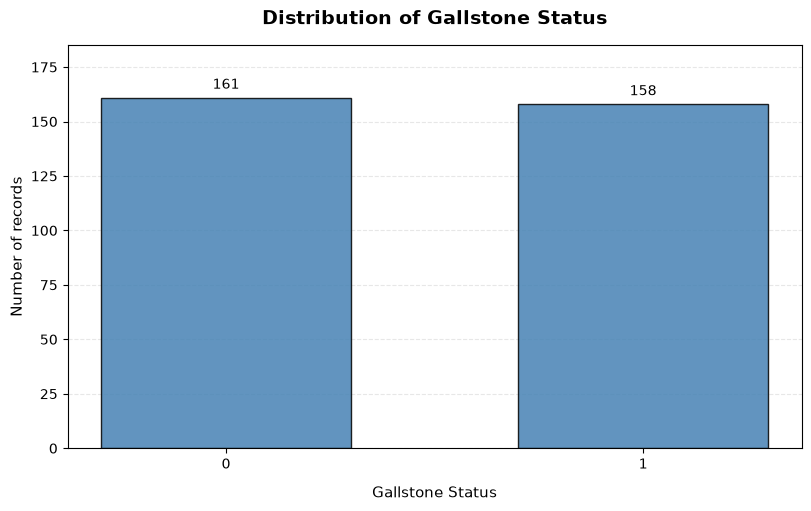

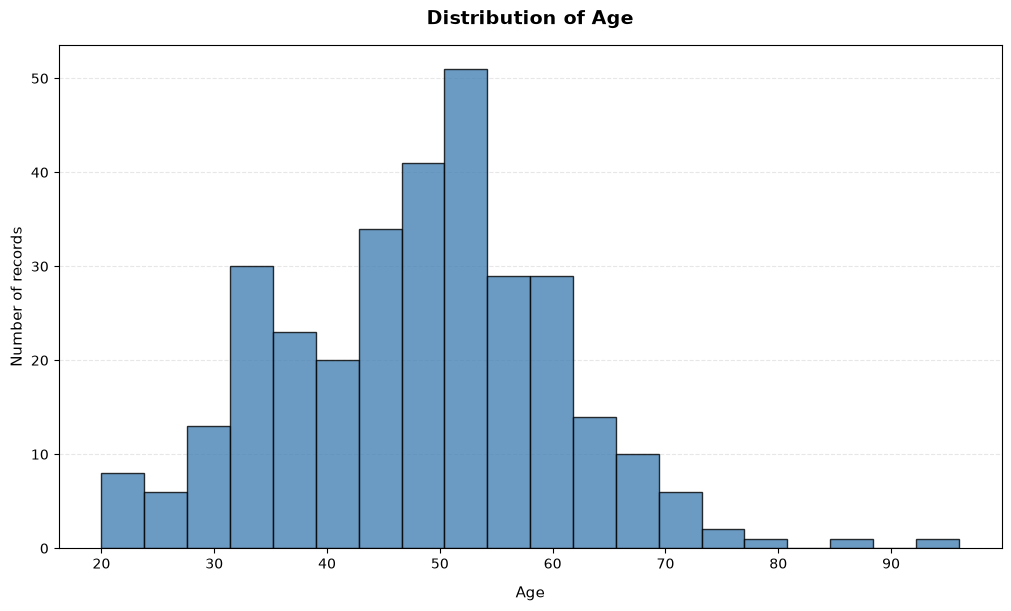

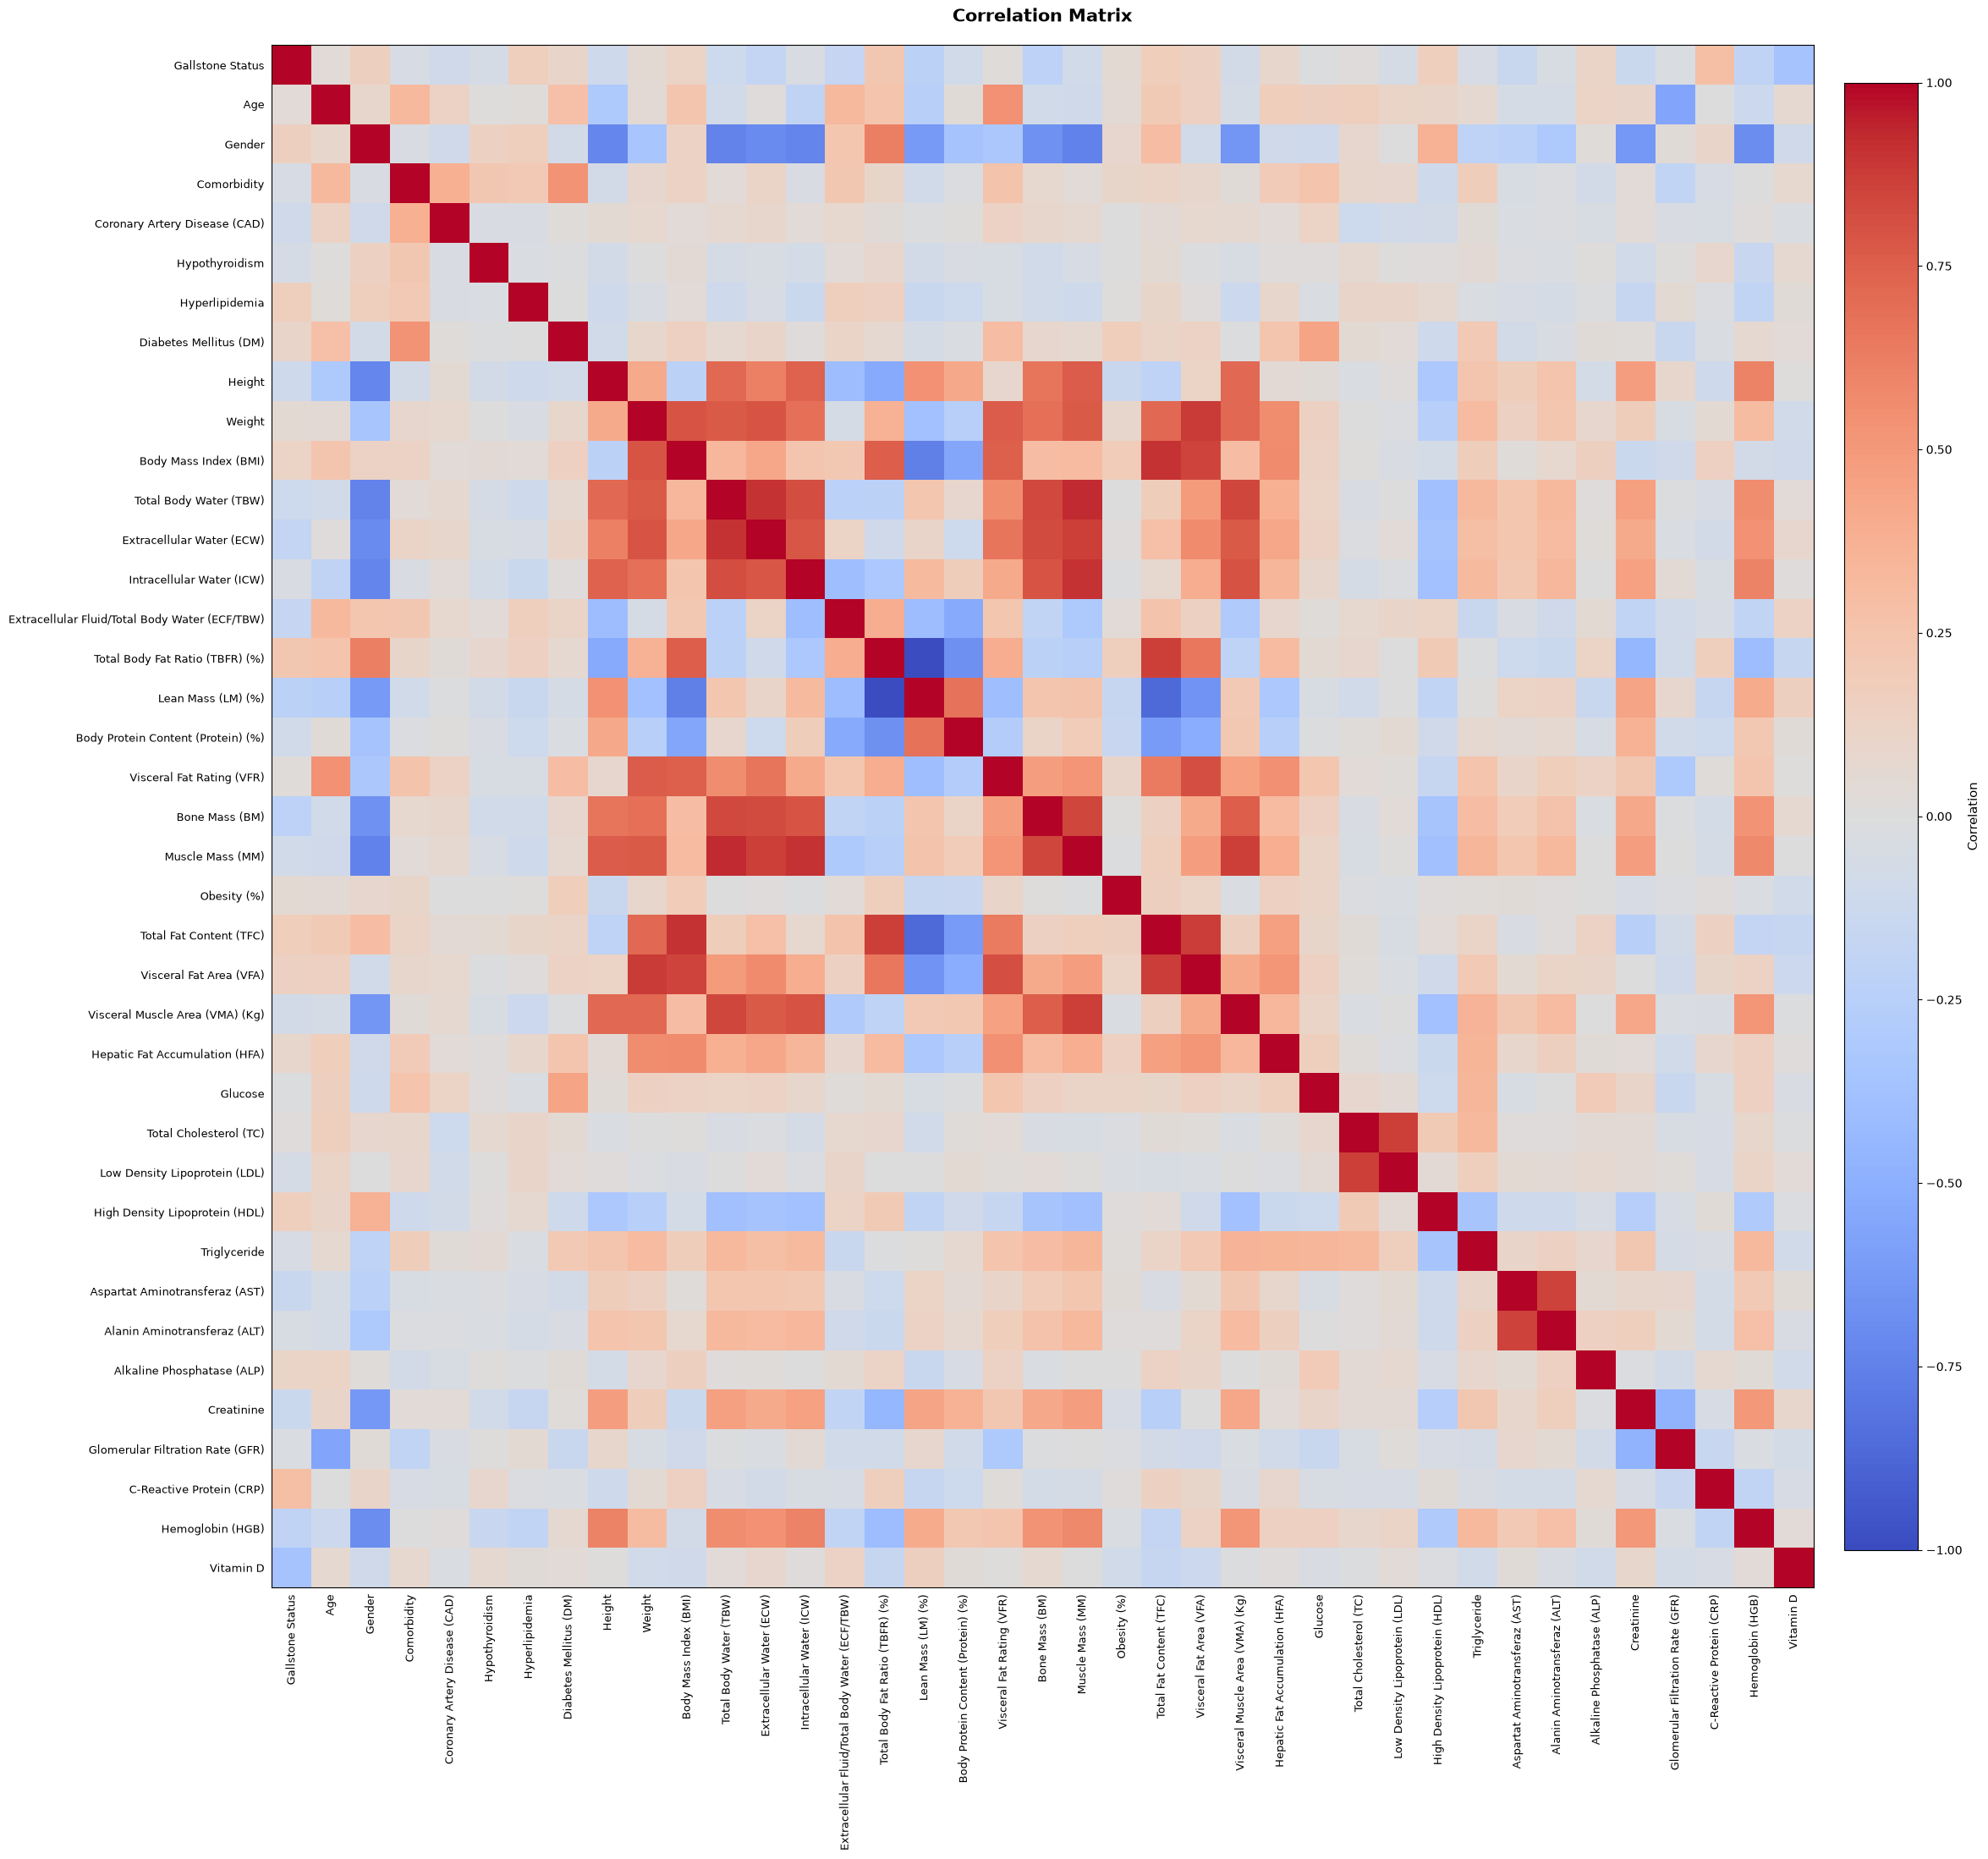

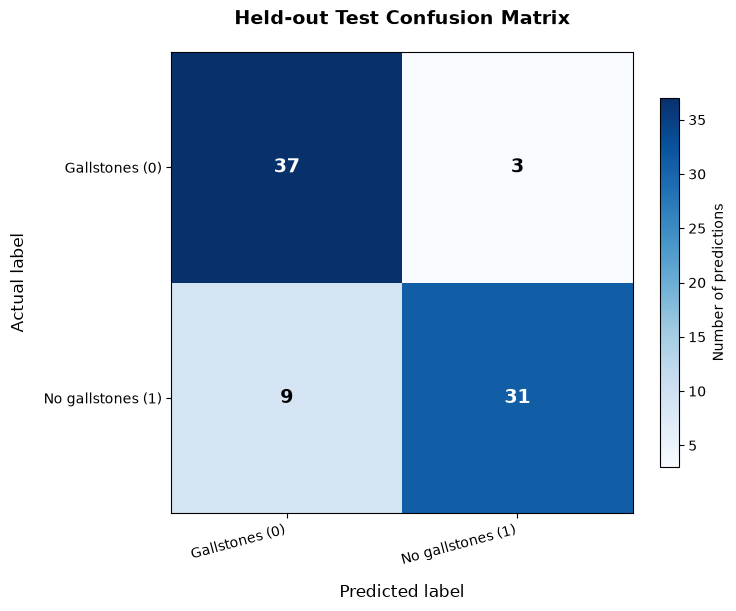

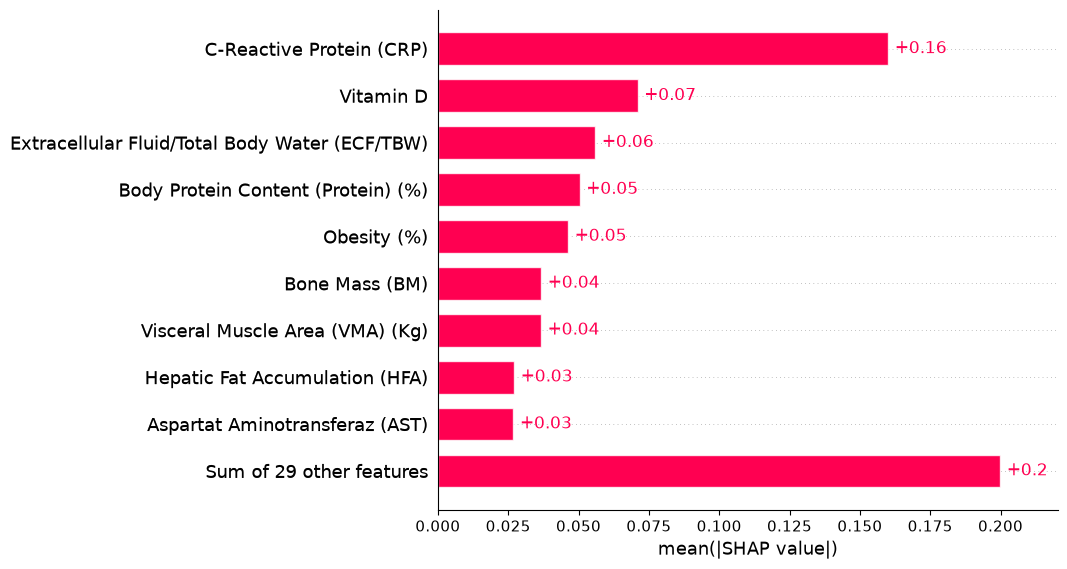

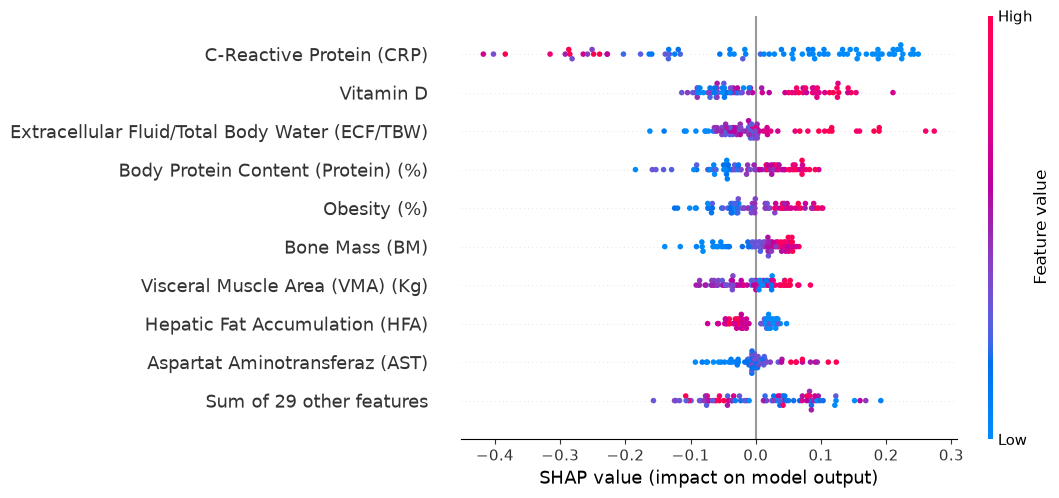

In [204]:
visualizer = DataVisualizer(data)
visualizer.plot_target_distribution(target="Gallstone Status")
plt.show()

visualizer.plot_feature_distribution(feature="Age")
plt.show()

visualizer.plot_correlation_matrix()
plt.show()

# Use the same threshold and model as the printed evaluation.
test_predictions = trainer.predict(model, trainer.X_test)["predictions"]
visualizer.plot_confusion_matrix(
    actual=trainer.y_test,
    predicted=test_predictions,
)
plt.show()

# SHAP is optional and is run after model evaluation.
explanations = trainer.explain(model)
shap.plots.bar(explanations, show=True)
plt.show()
shap.plots.beeswarm(explanations, show=True)
plt.show()
